## Carga librerias

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import roc_auc_score, brier_score_loss
import statsmodels.api as sm
import scipy
from sklearn.isotonic import IsotonicRegression

## Parametrizacion

In [ ]:
PATH_DATA = r"./data/"
FILE_BASE = fr"{PATH_DATA}base_desembolsos_clientes_v6_shift.csv"

DICT_MESES = {
    "01": "Ene",
    "02": "Feb",
    "03": "Mar",
    "04": "Abr",
    "05": "May",
    "06": "Jun",
    "07": "Jul",
    "08": "Ago",
    "09": "Sep",
    "10": "Oct",
    "11": "Nov",
    "12": "Dic"
}

In [ ]:
sns.set_theme(
    context="paper",
    style="white",
    rc={
        "axes.spines.bottom": True,
        "axes.spines.top": False,
        "axes.spines.left": False,
        "axes.spines.right": False,
        "xtick.bottom": False,
        "ytick.left": False,
        "ytick.right": False,
    }
)

## Carga de la base

In [ ]:
df = pd.read_csv(FILE_BASE, sep=",", encoding="latin-1",)
# df.info()
print(df["periodo_desembolso"].min(), df["periodo_desembolso"].max())
df = df[df["periodo_desembolso"] >= 202401]
df.head()

202001 202606


,periodo_desembolso,id_cliente,monto_desembolso,apalancamiento,utilizacion_linea,antiguedad_sistema_financiero,pd_sin_calibrar,default_12m,default_11m,default_10m,default_9m,default_8m,default_7m,default_6m,default_3m
422765,202401,422766,57514.66,6.99,0.1857,309,0.1709,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
422766,202401,422767,67015.27,4.10,0.3216,44,0.0870,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
422767,202401,422768,15076.01,7.55,0.0836,325,0.2815,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
422768,202401,422769,62270.39,4.56,0.1221,156,0.1311,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
422769,202401,422770,33210.03,3.26,0.3349,42,0.1256,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Pinta el grafico de PD vs RD con lo intervalos de Vasicek

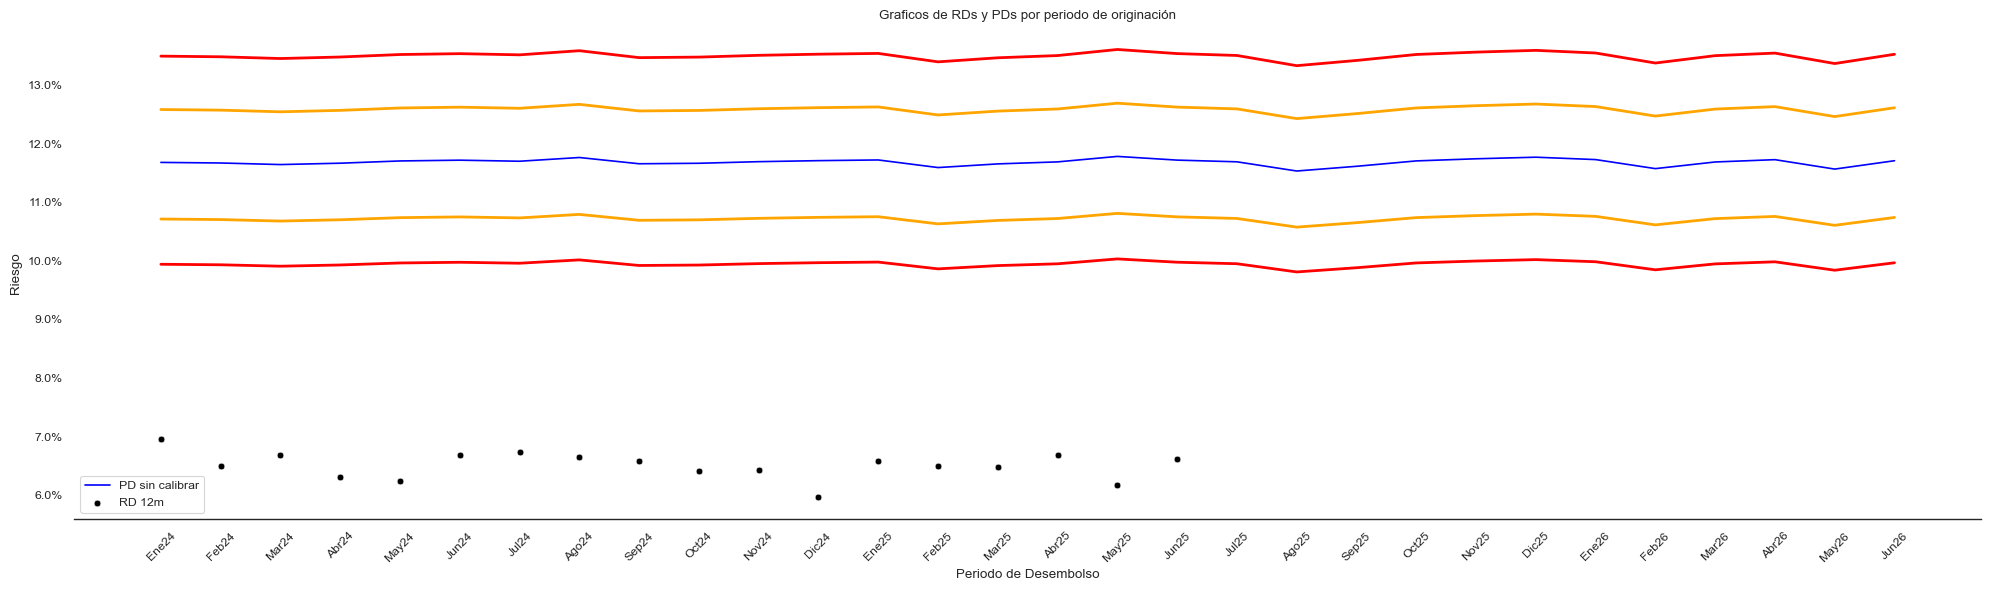

In [ ]:
df_plot = df.groupby(["periodo_desembolso"], as_index=False).agg(
    saldo=("monto_desembolso", "sum"),
    pd=("pd_sin_calibrar", "mean"),
    rd12=("default_12m", "mean"),
)
df_plot["periodo_desembolso_str"] = df_plot["periodo_desembolso"].astype(str)
df_plot["periodo_desembolso_str"] = df_plot["periodo_desembolso_str"].str[4:].map(lambda x: DICT_MESES.get(x)) + df_plot["periodo_desembolso_str"].str[2:4]


df_plot["inf_25"] = scipy.stats.norm.cdf(
    (1-0.005) ** (-0.5) * scipy.stats.norm.ppf(df_plot["pd"])
    + (0.005 / (1 - 0.005)) **   0.5 * scipy.stats.norm.ppf(25 / 100)
    )
df_plot["sup_75"] = scipy.stats.norm.cdf(
    (1-0.005) ** (-0.5) * scipy.stats.norm.ppf(df_plot["pd"])
    + (0.005 / (1 - 0.005)) ** 0.5 * scipy.stats.norm.ppf(75 / 100)
    )
df_plot["inf_10"] = scipy.stats.norm.cdf(
    (1-0.005) ** (-0.5) * scipy.stats.norm.ppf(df_plot["pd"])
    + (0.005 / (1 - 0.005)) ** 0.5 * scipy.stats.norm.ppf(10 / 100)
    )
df_plot["sup_90"] = scipy.stats.norm.cdf(
    (1-0.005) ** (-0.5) * scipy.stats.norm.ppf(df_plot["pd"])
    + (0.005 / (1 - 0.005)) ** 0.5 * scipy.stats.norm.ppf(90 / 100)
    )


plt.figure(figsize=(20, 6))
sns.lineplot(data=df_plot, x="periodo_desembolso_str", y="pd", label="PD sin calibrar", color="blue")
sns.scatterplot(data=df_plot, x="periodo_desembolso_str", y="rd12", label="RD 12m", color="black")
sns.lineplot(data=df_plot, y='inf_25', x='periodo_desembolso_str',
        linestyle='-', linewidth=2, markersize=8, label=None, color='orange')
sns.lineplot(data=df_plot, y='sup_75', x='periodo_desembolso_str',
        linestyle='-', linewidth=2, markersize=8, label=None, color='orange')
sns.lineplot(data=df_plot, y='inf_10', x='periodo_desembolso_str',
        linestyle='-', linewidth=2, markersize=8, label=None, color='red')
sns.lineplot(data=df_plot, y='sup_90', x='periodo_desembolso_str',
        linestyle='-', linewidth=2, markersize=8, label=None, color='red')

plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax=1))

plt.title(f"Graficos de RDs y PDs por periodo de originación")
plt.xlabel("Periodo de Desembolso")
plt.ylabel("Riesgo")

plt.xticks(rotation=45)

plt.legend()
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

plt.tight_layout()
plt.grid(False)

plt.show()
plt.close()

* ¿Está la PD calibrada?
* ¿Se está subestimando o sobrestimando el riesgo?

No está la PD calibrada, de hecho está sobrestimando el riesgo, ya que estoy diciendo que hay mucho más riesgo del que realmente hay

### Calcula el gini del modelo en los últimos 3 meses

### Identifica variables que aporten

In [ ]:
rd12_periodos_sorted = sorted(df.loc[(df["default_12m"].notna()), "periodo_desembolso"].unique())
rd12_last3m = rd12_periodos_sorted[-3:]
rd12_last6m = rd12_periodos_sorted[-6:]
rd12_last1m = rd12_periodos_sorted[-1]

In [ ]:
roc_auc_12m_u3m = roc_auc_score(
    df.loc[df["periodo_desembolso"].isin(rd12_last3m), "default_12m"],
    df.loc[df["periodo_desembolso"].isin(rd12_last3m), "pd_sin_calibrar"],
)
print(fr"Gini de los últimos 3 meses con target a 12 meses: {2 * roc_auc_12m_u3m - 1:.1%}")

Gini de los últimos 3 meses con target a 12 meses: 25.0%


* ¿Qué gini tiene la PD?
* A niveles generales de modelos de riesgo, ¿es un gini alto o bajo?

El modelo de la PD sin calibrar tiene un gini de un 25%, lo cual es bajo para un modelo de riesgos

### Identifica variables que aporten discriminación y precisión al modelo

In [ ]:
def percentiles(feature: pd.Series, k: int, ls_valores_especiales=None):
    """
    Calcula percentiles de una variable continua, separando missing
    y valores especiales (que no computan en los cortes).

    Retorna np.array de etiquetas: '01. <=x', ..., '-1. ESP_v', '-99. MISSING'
    """
    especiales = list(ls_valores_especiales) if ls_valores_especiales else []

    mask_esp = feature.isin(especiales)
    mask_na = feature.isna()
    mask_ok = ~mask_esp & ~mask_na

    feat_ok = feature[mask_ok]

    # Cortes por percentiles (solo sobre valores válidos)
    # print(k)
    # print(np.linspace(0, 1, k + 1)[1:])
    limites = np.linspace(0, 1, k + 1)[1:]          # descartamos el 0: buckets 0..k-1
    ranks = feat_ok.rank(pct=True).values
    buckets = np.searchsorted(limites, ranks, side="left")
    buckets = np.clip(buckets, 0, k - 1)            # el rank 1.0 cae en el último bucket

    # Etiquetas de cada bucket con su valor máximo
    values_max = feat_ok.groupby(buckets).max()
    dict_translate = {
        str(idx): f"{str(idx).zfill(2)}. <={round(val, 4)}"
        for idx, val in values_max.items()
    }

    # Códigos especiales: -1, -2, ... (nunca 0, para no chocar con buckets)
    for i, v in enumerate(especiales):
        dict_translate[str(-(i + 1))] = f"{-(i + 1)}. ESP_{v}"
    dict_translate["-99"] = "-99. MISSING"

    # Array de salida a longitud completa, alineado con feature
    out = np.full(len(feature), -99, dtype=int)     # por defecto missing
    out[mask_ok.values] = buckets
    for i, v in enumerate(especiales):
        out[(feature == v).values] = -(i + 1)

    return pd.Series(out, index=feature.index).astype(str) \
             .map(lambda c: dict_translate.get(c, "99. ERROR")).values

def plot_bivariado(df, feat, rd_feat, pd_feat, flg_ctd_pct=True):

    fig, axs = plt.subplots(figsize=(10, 5), constrained_layout=True)
    axs.set_title(fr"Bivariado {feat}")

    df_plot = df.groupby([feat], as_index=False, dropna=False).agg(
        PORCENTAJE=(feat, "count"), RD=(rd_feat, "mean"), PD=(pd_feat, "mean")
    )

    if flg_ctd_pct:
        df_plot["PORCENTAJE"] = round(100 * df_plot["PORCENTAJE"] / df_plot["PORCENTAJE"].sum(), 2)

    # ---- twin explícito, con referencia ----
    ax2 = axs.twinx()

    barplot = sns.barplot(
        x=df_plot[feat], y=df_plot["PORCENTAJE"],
        ax=ax2, color="lightgreen"
    )
    for container in barplot.containers:
        barplot.bar_label(container, padding=3)

    # ---- formato del twin: sin grid, sin spines, detrás del eje principal ----
    ax2.grid(False)
    for spine in ["top", "right", "left"]:
        ax2.spines[spine].set_visible(False)
    ax2.tick_params(axis="y", which="both", right=False, labelright=True)
    ax2.set_ylabel("")
    ax2.set_zorder(1)

    # ---- eje principal por encima y con fondo transparente ----
    axs.set_zorder(2)
    axs.patch.set_visible(False)   # si no, el fondo de axs tapa las barras

    df_plot["inf_25"] = scipy.stats.norm.cdf(
        (1-0.005) ** (-0.5) * scipy.stats.norm.ppf(df_plot["PD"])
        + (0.005 / (1 - 0.005)) ** 0.5 * scipy.stats.norm.ppf(25 / 100)
        )
    df_plot["sup_75"] = scipy.stats.norm.cdf(
        (1-0.005) ** (-0.5) * scipy.stats.norm.ppf(df_plot["PD"])
        + (0.005 / (1 - 0.005)) ** 0.5 * scipy.stats.norm.ppf(75 / 100)
        )
    df_plot["inf_10"] = scipy.stats.norm.cdf(
        (1-0.005) ** (-0.5) * scipy.stats.norm.ppf(df_plot["PD"])
        + (0.005 / (1 - 0.005)) ** 0.5 * scipy.stats.norm.ppf(10 / 100)
        )
    df_plot["sup_90"] = scipy.stats.norm.cdf(
        (1-0.005) ** (-0.5) * scipy.stats.norm.ppf(df_plot["PD"])
        + (0.005 / (1 - 0.005)) ** 0.5 * scipy.stats.norm.ppf(90 / 100)
        )

    sns.scatterplot(x=df_plot[feat], y=df_plot["RD"], ax=axs, color="black", zorder=10)
    sns.lineplot(x=df_plot[feat], y=df_plot["PD"], ax=axs, color="blue", zorder=11)

    sns.lineplot(data=df_plot, y='inf_25', x=feat, ax=axs,
            linestyle='-', linewidth=2, markersize=8, label=None, color='orange', zorder=11)
    sns.lineplot(data=df_plot, y='sup_75', x=feat, ax=axs,
            linestyle='-', linewidth=2, markersize=8, label=None, color='orange', zorder=11)
    sns.lineplot(data=df_plot, y='inf_10', x=feat, ax=axs,
            linestyle='-', linewidth=2, markersize=8, label=None, color='red', zorder=11)
    sns.lineplot(data=df_plot, y='sup_90', x=feat, ax=axs,
            linestyle='-', linewidth=2, markersize=8, label=None, color='red', zorder=11)

    # ---- formato del eje principal ----
    axs.grid(False)
    for spine in ["top", "right", "left"]:
        axs.spines[spine].set_visible(False)
    axs.set_xlabel("")
    axs.tick_params(axis="x", labelrotation=90)
    axs.tick_params(axis="y", which="both", left=False, labelleft=True)

    axs.set_ylim(0, 0.12)

    plt.show()
    plt.close()

def plot_bivariados_percentile(df, feat_name, k: int, rd_feat, pd_feat, ls_valores_especiales=None, flg_ctd_pct=True):
    """
    """
    df_aux = df.copy()
    df_aux[fr"PERCENTILES_{feat_name}"] = percentiles(df_aux[feat_name], k, ls_valores_especiales)
    plot_bivariado(df_aux, fr"PERCENTILES_{feat_name}", rd_feat, pd_feat, flg_ctd_pct)


In [ ]:
df["xb_sin_calibrar"] = np.log(df[['pd_sin_calibrar',]] / (1. - df[['pd_sin_calibrar',]]))
df_model = df[(df["default_12m"].notna()) & (df["periodo_desembolso"].isin(rd12_last6m))]
X = df_model[["xb_sin_calibrar",]]
X = sm.add_constant(X)
y = df_model['default_12m']

modelo = sm.GLM(
    y,
    X,
    family=sm.families.Binomial(link=sm.families.links.Logit())
)

resultado = modelo.fit()
print(resultado.summary())

df["pd_calibrada_rd12m_ult6m_platt"] = resultado.predict(sm.add_constant(df[["xb_sin_calibrar",]]))

                 Generalized Linear Model Regression Results                  
Dep. Variable:            default_12m   No. Observations:                53834
Model:                            GLM   Df Residuals:                    53832
Model Family:                Binomial   Df Model:                            1
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -12667.
Date:                Sat, 25 Jul 2026   Deviance:                       25334.
Time:                        10:23:49   Pearson chi2:                 5.36e+04
No. Iterations:                     6   Pseudo R-squ. (CS):            0.01064
Covariance Type:            nonrobust                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              -1.1691      0.063    -

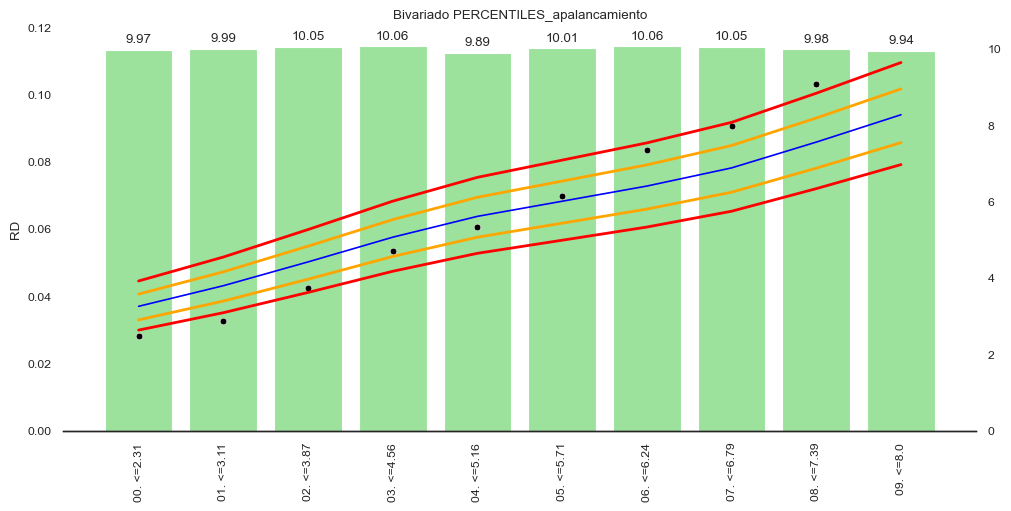

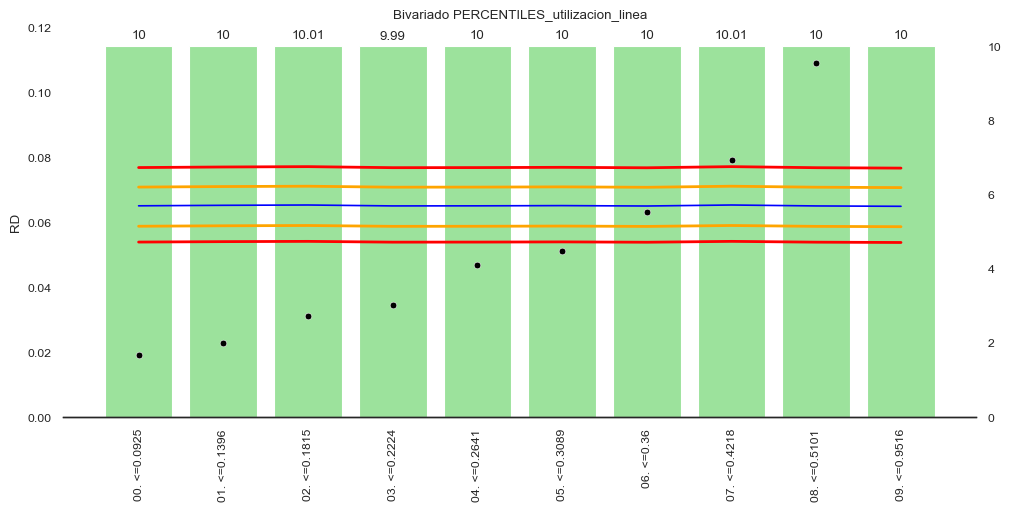

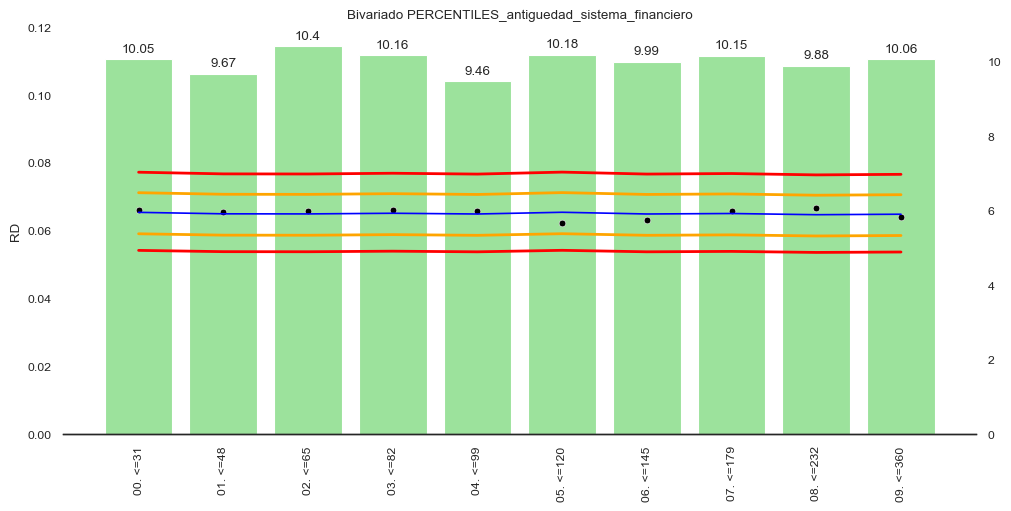

In [ ]:
for f in ["apalancamiento", "utilizacion_linea","antiguedad_sistema_financiero"]:
    plot_bivariados_percentile(df, f, k=10, rd_feat="default_12m", pd_feat="pd_calibrada_rd12m_ult6m_platt",)

* ¿Qué drivers identificas que aporten valor a la discrimnación?
* ¿Qué driver dirías que no aporta nada a nivel de discriminación ni precision?

A primera vista diría que los drivers que podrían aportar valor son el apalancamiento (más a nivel de precision) y la utilización de linea. En especial, este último donde se observa que la PD no recoge nada el riesgo, ya que es flat mientras que el riesgo es creciente.

### Calibra el modelo (Platt Scaling ó Isotonic Regression)

In [ ]:
df_model = df[(df["default_12m"].notna()) & (df["periodo_desembolso"].isin(rd12_last6m))]

iso = IsotonicRegression(y_min=0, y_max=1, out_of_bounds='clip')
iso.fit(df_model[['pd_sin_calibrar',]], df_model['default_12m'])

df["pd_calibrada_rd12m_ult6m_iso"] = iso.predict(df[["pd_sin_calibrar"]])

C:\Users\34660\AppData\Local\Temp\ipykernel_16048\3393133843.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_curva_calibracion_pd_raw = df_curva_calibracion_pd_raw.groupby('decil', as_index=False).agg(
C:\Users\34660\AppData\Local\Temp\ipykernel_16048\3393133843.py:31: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_curva_calibracion_pd_platt = df_curva_calibracion_pd_platt.groupby('decil', as_index=False).agg(
C:\Users\34660\AppData\Local\Temp\ipykernel_16048\3393133843.py:48: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass o

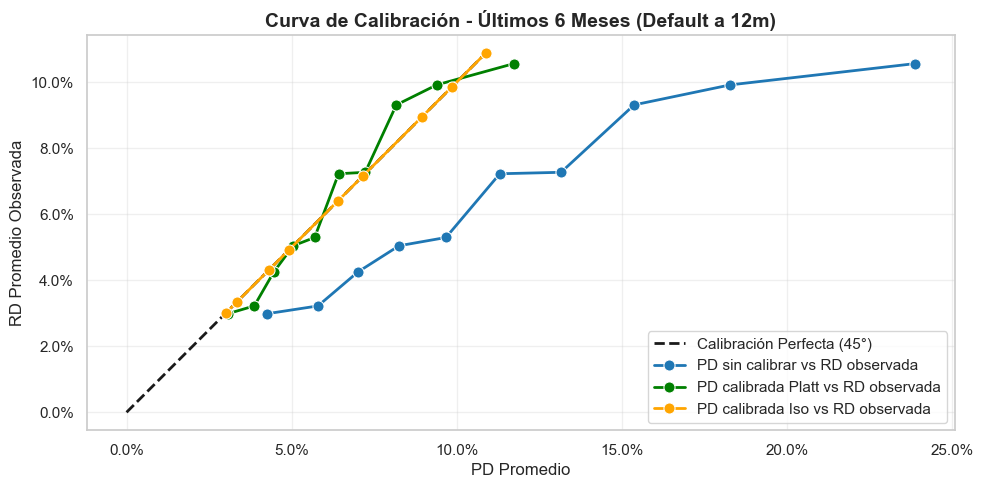

In [ ]:
# Crear curvas de calibración
# Preparar datos para los últimos 6 meses
df_curva_calibracion_pd_raw = df.loc[(df['periodo_desembolso'].isin(rd12_last6m))].copy()
df_curva_calibracion_pd_raw = df_curva_calibracion_pd_raw.dropna(subset=['default_12m', 'pd_sin_calibrar'])

# Ordenar por PD sin calibrar
df_curva_calibracion_pd_raw = df_curva_calibracion_pd_raw.sort_values('pd_sin_calibrar').reset_index(drop=True)

# Crear deciles de PD sin calibrar
df_curva_calibracion_pd_raw['decil'] = pd.qcut(df_curva_calibracion_pd_raw['pd_sin_calibrar'], q=10, duplicates='drop')

# Agrupar por deciles y calcular RD promedio
df_curva_calibracion_pd_raw = df_curva_calibracion_pd_raw.groupby('decil', as_index=False).agg(
    pd_promedio=('pd_sin_calibrar', 'mean'),
    rd_promedio=('default_12m', 'mean'),
    cantidad=('default_12m', 'count')
)

# Crear curvas de calibración
# Preparar datos para los últimos 6 meses
df_curva_calibracion_pd_platt = df.loc[(df['periodo_desembolso'].isin(rd12_last6m))].copy()
df_curva_calibracion_pd_platt = df_curva_calibracion_pd_platt.dropna(subset=['default_12m', 'pd_calibrada_rd12m_ult6m_platt'])

# Ordenar por PD calibrada
df_curva_calibracion_pd_platt = df_curva_calibracion_pd_platt.sort_values('pd_calibrada_rd12m_ult6m_platt').reset_index(drop=True)

# Crear deciles de PD calibrada
df_curva_calibracion_pd_platt['decil'] = pd.qcut(df_curva_calibracion_pd_platt['pd_calibrada_rd12m_ult6m_platt'], q=10, duplicates='drop')

# Agrupar por deciles y calcular RD promedio
df_curva_calibracion_pd_platt = df_curva_calibracion_pd_platt.groupby('decil', as_index=False).agg(
    pd_promedio=('pd_calibrada_rd12m_ult6m_platt', 'mean'),
    rd_promedio=('default_12m', 'mean'),
    cantidad=('default_12m', 'count')
)
# Crear curvas de calibración
# Preparar datos para los últimos 6 meses
df_curva_calibracion_pd_iso = df.loc[(df['periodo_desembolso'].isin(rd12_last6m))].copy()
df_curva_calibracion_pd_iso = df_curva_calibracion_pd_iso.dropna(subset=['default_12m', 'pd_calibrada_rd12m_ult6m_iso'])

# Ordenar por PD calibrada
df_curva_calibracion_pd_iso = df_curva_calibracion_pd_iso.sort_values('pd_calibrada_rd12m_ult6m_iso').reset_index(drop=True)

# Crear deciles de PD calibrada
df_curva_calibracion_pd_iso['decil'] = pd.qcut(df_curva_calibracion_pd_iso['pd_calibrada_rd12m_ult6m_iso'], q=10, duplicates='drop')

# Agrupar por deciles y calcular RD promedio
df_curva_calibracion_pd_iso = df_curva_calibracion_pd_iso.groupby('decil', as_index=False).agg(
    pd_promedio=('pd_calibrada_rd12m_ult6m_iso', 'mean'),
    rd_promedio=('default_12m', 'mean'),
    cantidad=('default_12m', 'count')
)

# Configurar estilo de seaborn
sns.set_theme(style='whitegrid')

# Crear gráfico
fig, ax = plt.subplots(figsize=(10, 8))

# Línea de calibración perfecta (45 grados)
min_val = 0
max_val = max(df_curva_calibracion_pd_iso['pd_promedio'].max(), df_curva_calibracion_pd_iso['rd_promedio'].max())
ax.plot([min_val, max_val], [min_val, max_val], 'k--', linewidth=2, label='Calibración Perfecta (45°)')

# Curva de calibración con seaborn
sns.lineplot(
    data=df_curva_calibracion_pd_raw,
    x='pd_promedio',
    y='rd_promedio',
    marker='o',
    markersize=8,
    linewidth=2,
    color='#1f77b4',
    label='PD sin calibrar vs RD observada',
    ax=ax
)
sns.lineplot(
    data=df_curva_calibracion_pd_platt,
    x='pd_promedio',
    y='rd_promedio',
    marker='o',
    markersize=8,
    linewidth=2,
    color='green',
    label='PD calibrada Platt vs RD observada',
    ax=ax,
)
sns.lineplot(
    data=df_curva_calibracion_pd_iso,
    x='pd_promedio',
    y='rd_promedio',
    marker='o',
    markersize=8,
    linewidth=2,
    color='orange',
    label='PD calibrada Iso vs RD observada',
    ax=ax,
)

ax.set_xlabel('PD Promedio', fontsize=12)
ax.set_ylabel('RD Promedio Observada', fontsize=12)
ax.set_title('Curva de Calibración - Últimos 6 Meses (Default a 12m)', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.set_aspect('equal')
# ax.set_xlim(0, 1)
# ax.set_ylim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
plt.close()

In [ ]:
roc_auc_12m_u3m = roc_auc_score(
    df.loc[df["periodo_desembolso"].isin(rd12_last3m), "default_12m"],
    df.loc[df["periodo_desembolso"].isin(rd12_last3m), "pd_calibrada_rd12m_ult6m_iso"],
)
print(fr"Gini de los últimos 3 meses con target a 12 meses (Isotonic): {2 * roc_auc_12m_u3m - 1:.1%}")

Gini de los últimos 3 meses con target a 12 meses (Isotonic): 25.6%


In [ ]:
roc_auc_12m_u3m = roc_auc_score(
    df.loc[df["periodo_desembolso"].isin(rd12_last3m), "default_12m"],
    df.loc[df["periodo_desembolso"].isin(rd12_last3m), "pd_calibrada_rd12m_ult6m_platt"],
)
print(fr"Gini de los últimos 3 meses con target a 12 meses (Platt): {2 * roc_auc_12m_u3m - 1:.1%}")

Gini de los últimos 3 meses con target a 12 meses (Platt): 25.0%


In [ ]:
df_model = df[(df["default_12m"].notna()) & (df["periodo_desembolso"].isin(rd12_last6m))]
X = df_model[[
    "xb_sin_calibrar",
    # "apalancamiento",
    "utilizacion_linea"]]
X = sm.add_constant(X)
y = df_model['default_12m']

modelo_v2 = sm.GLM(
    y,
    X,
    family=sm.families.Binomial(link=sm.families.links.Logit())
)

resultado_v2 = modelo_v2.fit()
print(resultado_v2.summary())

df["pd_calibrada_rd12m_ult6m_platt_v2"] = resultado_v2.predict(sm.add_constant(df[[
    "xb_sin_calibrar",
    # "apalancamiento",
    "utilizacion_linea"]]))

                 Generalized Linear Model Regression Results                  
Dep. Variable:            default_12m   No. Observations:                53834
Model:                            GLM   Df Residuals:                    53831
Model Family:                Binomial   Df Model:                            2
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -11656.
Date:                Sat, 25 Jul 2026   Deviance:                       23312.
Time:                        10:59:35   Pearson chi2:                 5.43e+04
No. Iterations:                     7   Pseudo R-squ. (CS):            0.04712
Covariance Type:            nonrobust                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -2.6599      0.07

In [ ]:
roc_auc_12m_u3m = roc_auc_score(
    df.loc[df["periodo_desembolso"].isin(rd12_last3m), "default_12m"],
    df.loc[df["periodo_desembolso"].isin(rd12_last3m), "pd_calibrada_rd12m_ult6m_platt_v2"],
)
print(fr"Gini de los últimos 3 meses con target a 12 meses (con drivers): {2 * roc_auc_12m_u3m - 1:.1%}")

Gini de los últimos 3 meses con target a 12 meses (con drivers): 48.4%


* Sin incluir drivers, ¿qué calibrado es màs preciso? ¿Por qué?
* ¿Qué calibrado se recomendaría? ¿Por qué?
* Si se incluyeron drivers ¿Qué drivers fueron?
* ¿Qué niveles de Gini obtienes cuando no incluyes drivers? ¿Y cuando incluyes drivers, qué niveles de gini se alcanzan?

Sin incluir drivers, es más preciso el isotónico, ya que al ser no paramétrico se ajusta mejor, mientras que el plat scaling, le falta información para que la PD se comporte como una sigmoide.

Observado los gráficos de los drivers recomendaría a primera instancia un claibrado platt scaling con los drivers de apalancamiento y utilización de linea.

A niveles de Gini se obtiene:

* Sin drivers:
    * Platt: 25%
    * Isotonic: 25.6%
* Con drivers:
    * Platt: 49.9%

### Calibra al nivel de la mora más reciente posible (se refiere a las proyeccciones de mora)

In [ ]:
df_seg = df.groupby(["periodo_desembolso"], as_index=False).agg(
    saldo=("monto_desembolso", "sum"),
    pd=("pd_calibrada_rd12m_ult6m_platt_v2", "mean"),
    rd12=("default_12m", "mean"),
    rd11=("default_11m", "mean"),
    rd10=("default_10m", "mean"),
    rd9=("default_9m", "mean"),
    rd8=("default_8m", "mean"),
    rd7=("default_7m", "mean"),
    rd6=("default_6m", "mean"),
    rd3=("default_3m", "mean")
).copy()


for i in range(6, 12):
    col_prev = fr"rd{i}"
    col_post = fr"rd{i+1}"

    index_last6_post_not_null = df_seg.loc[df_seg[col_post].notna(), col_post].tail(6)
    index_post_fill = df_seg.loc[df_seg[col_post].isna() & df_seg[col_prev].notna(), col_prev]
    # print(last6_prev)
    # print(last6_post)

    factor_mediana = (df_seg.loc[index_last6_post_not_null.index, f"{col_post}"] / df_seg.loc[index_last6_post_not_null.index, f"{col_prev}"]).median()

    df_seg.loc[index_post_fill.index, f"{col_post}"] = factor_mediana * df_seg.loc[index_post_fill.index, f"{col_prev}"]

    print(factor_mediana)



index_rd12_proy = df_seg.loc[df_seg["rd12"].notna(), "rd12"].tail(6)
df_seg["flg_rd_proy"] = np.nan
df_seg.loc[index_rd12_proy.index, "flg_rd_proy"] = 1.

df_seg["rd12_proy"] = df_seg["rd12"] * np.where(df_seg["flg_rd_proy"] == 1., 1., None)
df_seg["rd12"] = df_seg["rd12"] * np.where(df_seg["flg_rd_proy"].isna(), 1., None)


df_seg["periodo_desembolso_str"] = df_seg["periodo_desembolso"].astype(str)
df_seg["periodo_desembolso_str"] = df_seg["periodo_desembolso_str"].str[4:].map(lambda x: DICT_MESES.get(x)) + df_seg["periodo_desembolso_str"].str[2:4]

# df_seg.tail(12)

1.1444907345045894
1.128650137741047
1.1412915851272014
1.11012404046566
1.0889666748546631
1.0932544757033247


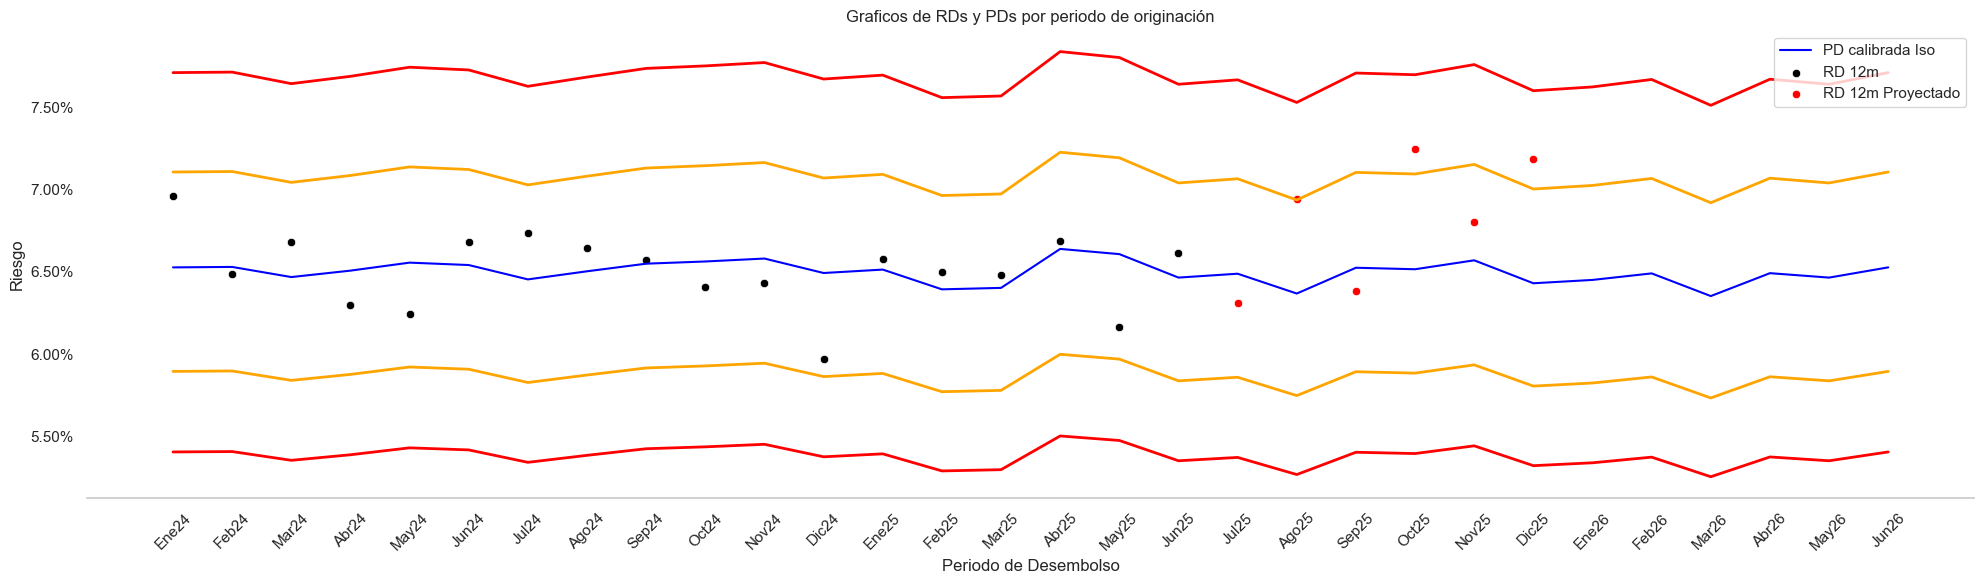

In [ ]:
df_seg["inf_25"] = scipy.stats.norm.cdf(
    (1-0.005) ** (-0.5) * scipy.stats.norm.ppf(df_seg["pd"])
    + (0.005 / (1 - 0.005)) ** 0.5 * scipy.stats.norm.ppf(25 / 100)
    )
df_seg["sup_75"] = scipy.stats.norm.cdf(
    (1-0.005) ** (-0.5) * scipy.stats.norm.ppf(df_seg["pd"])
    + (0.005 / (1 - 0.005)) ** 0.5 * scipy.stats.norm.ppf(75 / 100)
    )
df_seg["inf_10"] = scipy.stats.norm.cdf(
    (1-0.005) ** (-0.5) * scipy.stats.norm.ppf(df_seg["pd"])
    + (0.005 / (1 - 0.005)) ** 0.5 * scipy.stats.norm.ppf(10 / 100)
    )
df_seg["sup_90"] = scipy.stats.norm.cdf(
    (1-0.005) ** (-0.5) * scipy.stats.norm.ppf(df_seg["pd"])
    + (0.005 / (1 - 0.005)) ** 0.5 * scipy.stats.norm.ppf(90 / 100)
    )


plt.figure(figsize=(20, 6))
sns.lineplot(data=df_seg, x="periodo_desembolso_str", y="pd", label="PD calibrada Iso", color="blue")
sns.scatterplot(data=df_seg, x="periodo_desembolso_str", y="rd12", label="RD 12m", color="black")
sns.scatterplot(data=df_seg, x="periodo_desembolso_str", y="rd12_proy", label="RD 12m Proyectado", color="red")
sns.lineplot(data=df_seg, y='inf_25', x='periodo_desembolso_str',
        linestyle='-', linewidth=2, markersize=8, label=None, color='orange')
sns.lineplot(data=df_seg, y='sup_75', x='periodo_desembolso_str',
        linestyle='-', linewidth=2, markersize=8, label=None, color='orange')
sns.lineplot(data=df_seg, y='inf_10', x='periodo_desembolso_str',
        linestyle='-', linewidth=2, markersize=8, label=None, color='red')
sns.lineplot(data=df_seg, y='sup_90', x='periodo_desembolso_str',
        linestyle='-', linewidth=2, markersize=8, label=None, color='red')

plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax=1))

plt.title(f"Graficos de RDs y PDs por periodo de originación")
plt.xlabel("Periodo de Desembolso")
plt.ylabel("Riesgo")

plt.xticks(rotation=45)

plt.legend()
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

plt.tight_layout()
plt.grid(False)

plt.show()
plt.close()

In [ ]:
ls_periodos_calibrado = [
    # 202507,
    # 202508,
    # 202509,
    202510,
    202511,
    202512,
    ]
df_seg["factores"] = df_seg["rd12_proy"] / df_seg["pd"]
factor = df_seg[df_seg["periodo_desembolso"].isin(ls_periodos_calibrado)]["factores"].mean()

print(fr"Factor para calibrado de nivel: {factor: .2f}")

Factor para calibrado de nivel:  1.09


In [ ]:
df["xb_calibrada_rd12m_ult6m_platt_v2"] = np.log(df[['pd_calibrada_rd12m_ult6m_platt_v2',]] / (1. - df[['pd_calibrada_rd12m_ult6m_platt_v2',]]))

df_model = df[df["periodo_desembolso"].isin(ls_periodos_calibrado)].copy()

df_ones = df_model[["xb_calibrada_rd12m_ult6m_platt_v2", "pd_calibrada_rd12m_ult6m_platt_v2"]].copy()
df_ones["target"] = 1
df_ones["weights"] = (factor * df_ones["pd_calibrada_rd12m_ult6m_platt_v2"]).clip(0., 1.)

df_zeros = df_model[["xb_calibrada_rd12m_ult6m_platt_v2", "pd_calibrada_rd12m_ult6m_platt_v2"]].copy()
df_zeros["target"] = 0
df_zeros["weights"] = (1 - factor * df_zeros["pd_calibrada_rd12m_ult6m_platt_v2"]).clip(0., 1.)

df_model = pd.concat([df_ones, df_zeros], axis=0, ignore_index=True)

In [ ]:
X = df_model[['xb_calibrada_rd12m_ult6m_platt_v2',]]
X = sm.add_constant(X)
y = df_model['target']

modelo_nivel = sm.GLM(
    y,
    X,
    var_weights=df_model['weights'],
    family=sm.families.Binomial(link=sm.families.links.Logit())
)

resultado_nivel = modelo_nivel.fit()
print(resultado_nivel.summary())

df["pd_calibrada_rd12m_ult6m_platt_v2_nivel"] = resultado_nivel.predict(sm.add_constant(df[["xb_calibrada_rd12m_ult6m_platt_v2"]]))

                 Generalized Linear Model Regression Results                  
Dep. Variable:                 target   No. Observations:                53258
Model:                            GLM   Df Residuals:                    53256
Model Family:                Binomial   Df Model:                            1
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -6093.3
Date:                Sat, 25 Jul 2026   Deviance:                       12187.
Time:                        10:59:49   Pearson chi2:                 2.67e+04
No. Iterations:                     6   Pseudo R-squ. (CS):            0.02659
Covariance Type:            nonrobust                                         
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
const 

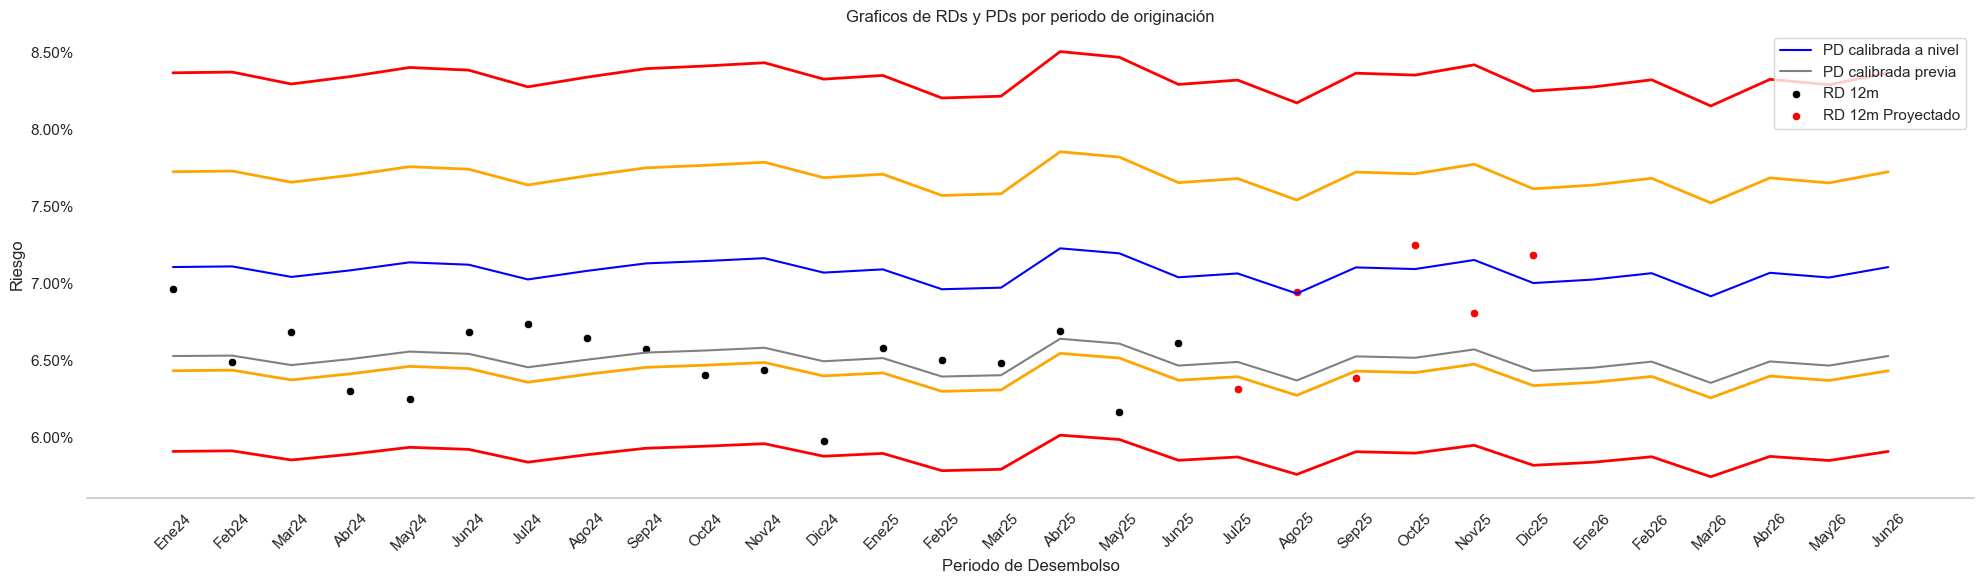

In [ ]:
df_plot = df.groupby(["periodo_desembolso"], as_index=False).agg(
    saldo=("monto_desembolso", "sum"),
    pd_prev=("pd_calibrada_rd12m_ult6m_platt_v2", "mean"),
    pd=("pd_calibrada_rd12m_ult6m_platt_v2_nivel", "mean"),
    rd12=("default_12m", "mean"),
    rd6=("default_6m", "mean"),
    rd3=("default_3m", "mean")
)
df_plot["periodo_desembolso_str"] = df_plot["periodo_desembolso"].astype(str)
df_plot["periodo_desembolso_str"] = df_plot["periodo_desembolso_str"].str[4:].map(lambda x: DICT_MESES.get(x)) + df_plot["periodo_desembolso_str"].str[2:4]


df_plot["inf_25"] = scipy.stats.norm.cdf(
    (1-0.005) ** (-0.5) * scipy.stats.norm.ppf(df_plot["pd"])
    + (0.005 / (1 - 0.005)) ** 0.5 * scipy.stats.norm.ppf(25 / 100)
    )
df_plot["sup_75"] = scipy.stats.norm.cdf(
    (1-0.005) ** (-0.5) * scipy.stats.norm.ppf(df_plot["pd"])
    + (0.005 / (1 - 0.005)) ** 0.5 * scipy.stats.norm.ppf(75 / 100)
    )
df_plot["inf_10"] = scipy.stats.norm.cdf(
    (1-0.005) ** (-0.5) * scipy.stats.norm.ppf(df_plot["pd"])
    + (0.005 / (1 - 0.005)) ** 0.5 * scipy.stats.norm.ppf(10 / 100)
    )
df_plot["sup_90"] = scipy.stats.norm.cdf(
    (1-0.005) ** (-0.5) * scipy.stats.norm.ppf(df_plot["pd"])
    + (0.005 / (1 - 0.005)) ** 0.5 * scipy.stats.norm.ppf(90 / 100)
    )


plt.figure(figsize=(20, 6))
sns.lineplot(data=df_plot, x="periodo_desembolso_str", y="pd", label="PD calibrada a nivel", color="blue")
sns.lineplot(data=df_plot, x="periodo_desembolso_str", y="pd_prev", label="PD calibrada previa", color="grey")
sns.scatterplot(data=df_plot, x="periodo_desembolso_str", y="rd12", label="RD 12m", color="black")
sns.scatterplot(data=df_seg, x="periodo_desembolso_str", y="rd12_proy", label="RD 12m Proyectado", color="red")
sns.lineplot(data=df_plot, y='inf_25', x='periodo_desembolso_str',
        linestyle='-', linewidth=2, markersize=8, label=None, color='orange')
sns.lineplot(data=df_plot, y='sup_75', x='periodo_desembolso_str',
        linestyle='-', linewidth=2, markersize=8, label=None, color='orange')
sns.lineplot(data=df_plot, y='inf_10', x='periodo_desembolso_str',
        linestyle='-', linewidth=2, markersize=8, label=None, color='red')
sns.lineplot(data=df_plot, y='sup_90', x='periodo_desembolso_str',
        linestyle='-', linewidth=2, markersize=8, label=None, color='red')

plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax=1))

plt.title(f"Graficos de RDs y PDs por periodo de originación")
plt.xlabel("Periodo de Desembolso")
plt.ylabel("Riesgo")

plt.xticks(rotation=45)

plt.legend()
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

plt.tight_layout()
plt.grid(False)

plt.show()
plt.close()

* ¿Qué periodos se utilizaron para el calibrado de nivel? ¿Por qué?
* En caso utiizaste varios drivers de calibración, observarás que la PD sube, ¿a qué se debe?

Los periodos utilizados son los 3 ultimos proyectados (oct25, nov25 y dic25). Se observa una subida de la PD que se debe a que el driver de apalancamiento ha sufrido un desplazamiento, por lo que se considera necesario quitarlo.

### Calcula los niveles de estabilidad de los 3 drivers de la base

In [ ]:
def calcular_psi_numerico(n_percentiles, periodos_referencia, periodo_calculo, df, var_col, periodo_col, valores_especiales=None, epsilon=1e-6, missing_label="MISSING"):
    """
    Calcula el Population Stability Index (PSI) para variables numéricas.

    Parámetros:
    - n_percentiles: Número de percentiles a utilizar para la segmentación.
    - periodos_referencia: Lista de periodos de referencia para calcular la distribución.
    - periodo_calculo: Periodo para el cual se calculará el PSI.
    - df: DataFrame que contiene los datos.
    - var_col: Nombre de la columna de la variable numérica.
    - periodo_col: Nombre de la columna que contiene los periodos.
    - valores_especiales: Lista de valores especiales.
    - epsilon: Valor pequeño para evitar logaritmos de cero.
    - missing_label: Etiqueta para valores faltantes.
    """
    especiales = list(valores_especiales) if valores_especiales else []
    ref = df[df[periodo_col].isin(periodos_referencia)][var_col]
    act = df[df[periodo_col] == periodo_calculo][var_col]

    if (len(ref) == 0) or (len(act) == 0):
        raise ValueError("No hay datos para el periodo de referencia o el periodo de cálculo.")
    # Bordes (percentiles). Solo con los valores normales de la referencia.
    ref_normal = ref[(~ref.isin(especiales)) & (~ref.isna())]
    if len(ref_normal) == 0:
        raise ValueError("No hay datos normales en el periodo de referencia.")
    bordes = np.unique(np.quantile(ref_normal, np.linspace(0, 1, n_percentiles + 1)))
    bordes[0], bordes[-1] = -np.inf, np.inf  # Asegurar que el primer y último borde sean -inf y +inf
    # Distribución de los tramos normales
    def dist_normal(s):
        total = len(s)
        normal = s[(~s.isin(especiales)) & (~s.isna())]
        vc = pd.cut(normal, bins=bordes, duplicates="drop").value_counts().sort_index()
        return vc / total if total else vc
    #
    norm = pd.DataFrame({
        "expected": dist_normal(ref),
        "actual": dist_normal(act)}).fillna(0)
    norm.index = norm.index.astype(str) # Mismos intervalos, mismas etiquetas
    # Distribución de los tramos especiales + missing
    def dist_especial(s):
        total = len(s)
        r={}
        for v in especiales:
            r[fr"ESP_{v}"] = ((s==v).sum() / total) if total else 0.
        r[missing_label] = (s.isna().sum() / total) if total else 0.
        return pd.Series(r, dtype=float)
    extra = pd.DataFrame({
        "expected": dist_especial(ref),
        "actual": dist_especial(act)}).fillna(0)
    t = pd.concat([norm, extra])
    t["expected"] = t["expected"].clip(lower=epsilon)
    t["actual"] = t["actual"].clip(lower=epsilon)
    t["psi"] = (t["actual"] - t["expected"]) * np.log(t["actual"] / t["expected"])
    t["codmes"] = periodo_calculo
    t["feature"] = var_col

    return {"psi": t["psi"].sum(), "detalle": t.reset_index().rename(columns={"index": "rango_valores"})}


def calcular_psi_categorico(periodos_referencia, periodo_calculo, df, var_col, periodo_col, valores_especiales=None, epsilon=1e-6, missing_label="MISSING"):
    """
    Calcula el Population Stability Index (PSI) para variables categóricas.

    Parámetros:
    - periodos_referencia: Lista de periodos de referencia para calcular la distribución.
    - periodo_calculo: Periodo para el cual se calculará el PSI.
    - df: DataFrame que contiene los datos.
    - var_col: Nombre de la columna de la variable categórica.
    - periodo_col: Nombre de la columna que contiene los periodos.
    - valores_especiales: Lista de valores especiales.
    - epsilon: Valor pequeño para evitar logaritmos de cero.
    - missing_label: Etiqueta para valores faltantes.
    """
    especiales = list(valores_especiales) if valores_especiales else []
    ref = df[df[periodo_col].isin(periodos_referencia)][var_col]
    act = df[df[periodo_col] == periodo_calculo][var_col]

    if (len(ref) == 0) or (len(act) == 0):
        raise ValueError("No hay datos para el periodo de referencia o el periodo de cálculo.")

    # Distribución de las categorías normales
    def dist_normal(s):
        total = len(s)
        normal = s[(~s.isin(especiales)) & (~s.isna())]
        vc = normal.value_counts()
        return vc / total if total else vc

    norm = pd.DataFrame({
        "expected": dist_normal(ref),
        "actual": dist_normal(act)}).fillna(0)
    norm.index = norm.index.astype(str)

    # Distribución de los valores especiales + missing
    def dist_especial(s):
        total = len(s)
        r = {}
        for v in especiales:
            r[fr"ESP_{v}"] = ((s == v).sum() / total) if total else 0.
        r[missing_label] = (s.isna().sum() / total) if total else 0.
        return pd.Series(r, dtype=float)

    extra = pd.DataFrame({
        "expected": dist_especial(ref),
        "actual": dist_especial(act)}).fillna(0)

    t = pd.concat([norm, extra])
    t["expected"] = t["expected"].clip(lower=epsilon)
    t["actual"] = t["actual"].clip(lower=epsilon)
    t["psi"] = (t["actual"] - t["expected"]) * np.log(t["actual"] / t["expected"])
    t["codmes"] = periodo_calculo
    t["feature"] = var_col

    return {"psi": t["psi"].sum(), "detalle": t.reset_index().rename(columns={"index": "categoria"})}

def color_psi(val):
    if val > 0.25:
        return 'background-color: #f4a6a6; color: black'   # rojo claro
    elif val > 0.10:
        return 'background-color: #fff3b0; color: black'   # amarillo claro
    else:
        return 'background-color: #b7e4a0; color: black'   # verde claro

In [ ]:

dict_psi_num = {
    "feature": [],
    "periodo_desembolso": [],
    "psi": [],
}
ls_dfs = []
for f in ["apalancamiento", "utilizacion_linea", "antiguedad_sistema_financiero"]:
    print(fr"{f}", end=": ")
    for p in df.loc[(df["periodo_desembolso"] > 202503), "periodo_desembolso"].unique().tolist():
        print(fr"{p}", end=";")
        resultado_psi_num = calcular_psi_numerico(
            n_percentiles=10,
            periodos_referencia=df.loc[(df["periodo_desembolso"] <= 202503), "periodo_desembolso"].unique().tolist(),
            periodo_calculo=p,
            df=df,
            var_col=f, periodo_col="periodo_desembolso",
            valores_especiales=None,
            epsilon=1e-6, missing_label="MISSING")

        dict_psi_num["feature"].append(f)
        dict_psi_num["periodo_desembolso"].append(p)
        dict_psi_num["psi"].append(resultado_psi_num['psi'])

        ls_dfs.append(resultado_psi_num["detalle"])
    print()

df_psi = pd.DataFrame(dict_psi_num).pivot_table(
    index='feature',
    columns='periodo_desembolso',
    values='psi',
    aggfunc='sum'   # o 'mean', 'count', etc.
).reset_index()
df_psi.columns.name = None
ls_columns = df_psi.filter(regex=r"\d{6}").columns.tolist()
df_psi.style.map(color_psi, subset=ls_columns)

apalancamiento: 202504;202505;202506;202507;202508;202509;202510;202511;202512;202601;202602;202603;202604;202605;202606;
utilizacion_linea: 202504;202505;202506;202507;202508;202509;202510;202511;202512;202601;202602;202603;202604;202605;202606;
antiguedad_sistema_financiero: 202504;202505;202506;202507;202508;202509;202510;202511;202512;202601;202602;202603;202604;202605;202606;


,feature,202504,202505,202506,202507,202508,202509,202510,202511,202512,202601,202602,202603,202604,202605,202606
0,antiguedad_sistema_financiero,0.001134,0.001987,0.001086,0.000941,0.001626,0.001846,0.000423,0.000778,0.000856,0.002114,0.000388,0.001419,0.000933,0.002005,0.000880
1,apalancamiento,0.001519,0.000742,0.000533,0.000612,0.001443,0.000892,0.000999,0.001231,0.001490,1.305862,1.271973,1.173389,1.233681,1.264291,1.358832
2,utilizacion_linea,0.001666,0.001387,0.001506,0.000265,0.000796,0.000617,0.000517,0.000834,0.001088,0.001266,0.000454,0.001986,0.001331,0.001434,0.001415


* ¿Cuáles son niveles de PSI de la PD?
* ¿Cuáles son los niveles de PSI de los drivers?
* ¿Son todos estables? ¿Por qué?
* Qué conclsuiones obtienes al ver los niveles del PSI

Se observa que el driver de apalancamiento no es estable en el tiempo, por lo que lo mejor sería quitarlo.

### Pinta los niveles de discriminación a nivel mensual

In [ ]:
dict_gini = {
    "periodo_desembolso": [],
    "gini_pd_sin_calibrar": [],
    "gini_pd_calibrada": [],
    "desembolso": [],
    "reg": [],
    "reg_rd12_na": [],
    "reg_pd_na": [],
}

for mes in sorted(df.loc[(df["periodo_desembolso"] <= rd12_last1m), "periodo_desembolso"].unique().tolist()):
    print(fr"{mes}", end=";")
    df_p = df[(df["periodo_desembolso"] == mes)]

    reg = df_p.shape[0]
    reg_rd12_na = df_p["default_12m"].isna()
    reg_pd_na = df_p["pd_sin_calibrar"].isna()

    df_p = df_p[(~reg_rd12_na) & (~reg_pd_na)]

    dict_gini["periodo_desembolso"].append(mes)
    roc_auc = roc_auc_score(df_p["default_12m"], df_p["pd_sin_calibrar"])
    dict_gini["gini_pd_sin_calibrar"].append(np.abs(2 * roc_auc - 1))
    roc_auc = roc_auc_score(df_p["default_12m"], df_p["pd_calibrada_rd12m_ult6m_platt_v2_nivel"])
    dict_gini["gini_pd_calibrada"].append(np.abs(2 * roc_auc - 1))
    dict_gini["desembolso"].append(df_p["monto_desembolso"].sum())
    dict_gini["reg"].append(reg)
    dict_gini["reg_rd12_na"].append(reg_rd12_na.sum())
    dict_gini["reg_pd_na"].append(reg_pd_na.sum())

202401;202402;202403;202404;202405;202406;202407;202408;202409;202410;202411;202412;202501;202502;202503;202504;202505;202506;

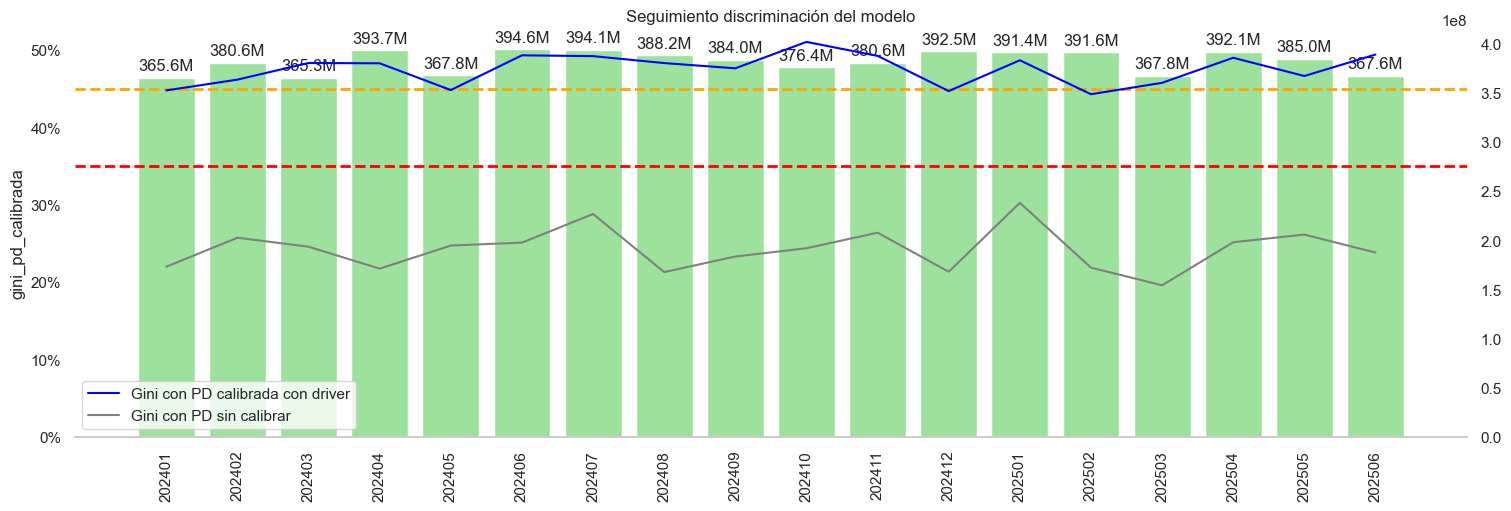

In [ ]:
fig, axs = plt.subplots(figsize=(15, 5), constrained_layout=True)
axs.set_title(r"Seguimiento discriminación del modelo")

df_plot = pd.DataFrame(dict_gini)

# ---- twin explícito, con referencia ----
ax2 = axs.twinx()

barplot = sns.barplot(
    x=df_plot["periodo_desembolso"].astype(str), y=df_plot["desembolso"],
    ax=ax2, color="lightgreen"
)
for container in barplot.containers:
    labels = [f'{v/1e6:.1f}M' for v in container.datavalues]
    barplot.bar_label(container, labels=labels, padding=3)

# ---- formato del twin: sin grid, sin spines, detrás del eje principal ----
ax2.grid(False)
for spine in ["top", "right", "left"]:
    ax2.spines[spine].set_visible(False)
ax2.tick_params(axis="y", which="both", right=False, labelright=True)
ax2.set_ylabel("")
ax2.set_zorder(1)

# ---- eje principal por encima y con fondo transparente ----
axs.set_zorder(2)
axs.patch.set_visible(False)   # si no, el fondo de axs tapa las barras

sns.lineplot(x=df_plot["periodo_desembolso"].astype(str), y=df_plot["gini_pd_calibrada"], ax=axs, color="blue", zorder=10, label="Gini con PD calibrada con driver")
sns.lineplot(x=df_plot["periodo_desembolso"].astype(str), y=df_plot["gini_pd_sin_calibrar"], ax=axs, color="grey", zorder=10, label="Gini con PD sin calibrar")
axs.set_ylim(bottom=0)

axs.axhline(y=0.45, color='orange', linestyle='--', linewidth=2)
axs.axhline(y=0.35, color='red', linestyle='--', linewidth=2)

# ---- formato del eje principal ----
axs.grid(False)
for spine in ["top", "right", "left"]:
    axs.spines[spine].set_visible(False)
axs.set_xlabel("")
axs.tick_params(axis="x", labelrotation=90)
axs.tick_params(axis="y", which="both", left=False, labelleft=True)

axs.yaxis.set_major_formatter(PercentFormatter(xmax=1))

plt.show()
plt.close()

* ¿Qué niveles de gini se obtienen?
* ¿Se mantiene estable el gini en el tiempo?

El gini se mantiene estable en el tiempo, entre valores de 45%-50%.

### Conslusiones

* Argumentar el calibrado final que se eligió

Se eligiría un calibrado Platt Scaling con el driver únicamente de utilización de línea por motivos de estabilidad, lo cual mejora al modelo en niveles de precisión y discriminación. El calibrado isotónico se descarta porque no admite drivers, donde el driver de utilización de línea es esencial por las mejoras que aporta